# STEAM-GAME-PROJECT — Phân tích dữ liệu Non-ML: Câu hỏi nghiên cứu 1

Notebook này triển khai câu hỏi nghiên cứu 1 (Q1) của nhóm theo chuẩn mực khoa học dữ liệu: phân tích ở cấp tựa game, sử dụng dữ liệu Steam tháng 03/2025 kết hợp dữ liệu nền tảng từ Hugging Face. Các kết quả chỉ mô tả mối liên hệ thống kê quan sát được, không suy diễn quan hệ nhân quả.

---

# 3.3. Xây dựng câu hỏi nghiên cứu

## 3.3.1. RQ1 — Mở rộng độ phủ và quy mô người sở hữu

### 1. Câu hỏi nghiên cứu

> “Số lượng ngôn ngữ và hệ điều hành được hỗ trợ có mối liên hệ như thế nào với lượng người sở hữu ước tính, và mối liên hệ này thay đổi ra sao khi xét đến thể loại và tuổi đời game?”

### 2. Động cơ nghiên cứu

Hỗ trợ thêm ngôn ngữ và nền tảng đòi hỏi chi phí bản địa hóa, phát triển và kiểm thử. Phân tích giúp mô tả mối liên hệ giữa độ phủ và quy mô sở hữu theo từng nhóm game, tránh áp dụng một chiến lược hỗ trợ cào bằng.

**Bên quan tâm:** Nhà phát triển, nhà phát hành, nhóm bản địa hóa (localization) và nhóm QA.

**Giá trị thực tiễn:** Hỗ trợ ra quyết định ưu tiên ngôn ngữ/nền tảng đầu tư và định vị phân khúc benchmark; không dùng kết quả để khẳng định tác động nhân quả.

### 3. Thuộc tính sử dụng và tích hợp dữ liệu

| Thuộc tính | Nguồn dữ liệu | Vai trò trong phân tích |
|---|---|---|
| `appid` / `appID` | Kaggle CSV và HF parquet | Khóa nối, định danh game và đơn vị phân tích. |
| `supported_languages` | Kaggle CSV | Nguồn tạo biến đếm `language_count`. |
| `windows`, `mac`, `linux` | HF parquet | Cờ hỗ trợ hệ điều hành; nguồn chính tạo `platform_count` cho game nối được. |
| `os` | Kaggle CSV | Đối chiếu số nền tảng và tính `platform_count` dự phòng cho game không khớp HF. |
| `estimated_owners` | Kaggle CSV | Kết quả dạng khoảng; cần quy tắc giá trị đại diện (`owner_midpoint`). |
| `genres`, `release_date`, `price` | Kaggle CSV | Phân tầng/điều chỉnh theo thể loại, tuổi đời và giá. |

**Tích hợp D1:** Nối `steam_games_mar2025.csv` với `hf_steam_games_dataset_train.parquet` theo `appid`/`appID` sau khi chuẩn hóa kiểu khóa. Dùng nối trái từ CSV chính để giữ nguyên đơn vị phân tích. Kiểm tra thực tế: 88.813/89.618 game khớp (99,1%); 805 game không khớp dùng danh sách `os` trong CSV làm nguồn dự phòng. Với game khớp, đối chiếu cho thấy số nền tảng giữa hai nguồn khác nhau ở 429 game (0,5% số game khớp). Báo cáo đầy đủ độ phủ nối và bất đồng nguồn trong kết quả.

### 4. Giả thuyết nghiên cứu

- **H1:** `language_count` và `platform_count` có mối liên hệ đồng biến với `owner_midpoint` ở cấp game.
- **H2:** Mức độ mối liên hệ giữa độ phủ hỗ trợ và lượng owner khác nhau giữa các nhóm `genres`.
- **H3:** Mức độ mối liên hệ thay đổi theo `game_age` khi xem xét `genres` và `price`.

### 5. Tiêu chí chiều sâu phân tích — dự kiến

| Tiêu chí | Phương pháp dự kiến | Mục tiêu |
|---|---|---|
| **D1 — Kết hợp dữ liệu** | Nối trái theo mã game (88.813/89.618 khớp); dùng ba cờ HF cho game khớp, dùng `os` CSV cho 805 game không khớp; đối chiếu số nền tảng (429 bất đồng). | Bổ sung và kiểm chứng thông tin nền tảng từ hai nguồn độc lập. |
| **D2 — Tái cấu trúc / Thời gian** | Dự kiến `explode()` `supported_languages` để tổng hợp ngôn ngữ; tính tuổi game từ mốc snapshot 31/03/2025. | Biểu diễn danh sách ngôn ngữ theo dạng dài và đưa tuổi đời vào so sánh. |
| **D3 — Biến dẫn xuất** | Tạo `language_count`, `platform_count`, `owner_midpoint`, `game_age`. | Định lượng độ phủ, quy mô người sở hữu đại diện và tuổi game với định nghĩa rõ ràng. |
| **D4 — Kiểm soát yếu tố gây nhiễu** | Xem xét `genres`, `price`, `game_age` qua phân tầng/điều chỉnh phù hợp. | Đánh giá mối liên hệ có điều kiện, tránh ngụy biện quan sát. |
| **D5 — Định lượng độ bất định** | Tính hệ số Spearman và khoảng tin cậy Bootstrap 95% (300 mẫu lặp lại). | Đo lường độ bất định lấy mẫu cho hệ số tương quan. |
| **D6 — Kiểm tra độ bền vững** | Thay `owner_midpoint` bằng `owner_low`, `owner_high`, loại bỏ khoảng `0–0`, giới hạn quantile 1%–99%, chia nhóm tuổi. | Đánh giá độ ổn định của kết luận trước các lựa chọn kỹ thuật. |

### 6. Giới hạn nghiên cứu

`estimated_owners` là khoảng ước tính, không phải số đếm chính xác; trung điểm chỉ là đại diện. Khoảng `0–0` chưa rõ ý nghĩa nguồn. Dữ liệu là quan sát cắt ngang tại một thời điểm, không phản ánh diễn tiến lịch sử hay quan hệ nhân quả.

# 3.4. Phân tích dữ liệu Non-ML


## 3.4.1. Phân tích Câu hỏi nghiên cứu 1: Độ phủ hỗ trợ và lượng người sở hữu (RQ1)

### 1. Mục tiêu nghiên cứu

Câu hỏi nghiên cứu: **“Số lượng ngôn ngữ và hệ điều hành được hỗ trợ có mối liên hệ như thế nào với lượng người sở hữu ước tính, và mối liên hệ này thay đổi ra sao khi xét đến thể loại và tuổi đời game?”** 

Phân tích mối liên hệ ở cấp tựa game, không diễn giải là quan hệ nhân quả.

### 2. Chuẩn bị dữ liệu

Một dòng tương ứng một `appid`. Các biến được chuẩn hóa trước khi tính số lượng, tuổi game và đại diện cho khoảng owner.

#### Thuộc tính và tích hợp dữ liệu

| Thuộc tính | Nguồn dữ liệu | Vai trò trong phân tích |
|---|---|---|
| `appid` / `appID` | CSV chính và HF parquet | Khóa nối, đơn vị phân tích ở cấp game. |
| `supported_languages`, `estimated_owners`, `genres`, `release_date`, `price` | CSV chính | Độ phủ ngôn ngữ, biến kết quả, nhóm thể loại, tuổi game và phân nhóm giá. |
| `os` | CSV chính | Đếm số nền tảng dự phòng và đối chiếu dữ liệu nền tảng. |
| `windows`, `mac`, `linux` | HF parquet | Ba cờ nền tảng dùng tính số hệ điều hành cho game nối được. |

**D1 – Kết hợp dữ liệu:** Nối `steam_games_mar2025.csv` với `hf_steam_games_dataset_train.parquet` theo `appid`/`appID` sau khi chuẩn hóa kiểu khóa; kiểm tra khóa duy nhất và dùng nối trái để giữ toàn bộ game trong CSV chính. Với game có bản ghi khớp, số nền tảng được tính từ ba cờ của HF; chỉ các game không khớp mới dùng danh sách `os` từ CSV. Đối chiếu số nền tảng giữa hai nguồn trên phần khớp và báo rõ độ phủ, số trường hợp không khớp. Các biến còn lại lấy từ CSV chính.

#### Cách phân tích

Phân tích chính dùng tương quan Spearman giữa độ phủ và `owner_midpoint`, sau đó so sánh theo thể loại, tuổi game và giá. Bootstrap cung cấp khoảng tin cậy 95%; các biến thể owner kiểm tra độ bền.

#### Tiêu chí chiều sâu

| Tiêu chí | Phương pháp | Mục tiêu |
|---|---|---|
| **D1 – Kết hợp dữ liệu** | Nối hai nguồn theo mã game; kiểm tra khóa, độ phủ nối và mức nhất quán của số nền tảng. | Bổ sung và đối chiếu thông tin nền tảng từ hai nguồn. |
| **D2 – Tái cấu trúc** | Tách danh sách thể loại thành bảng phụ, giữ `appid`; mỗi game chỉ tính một lần trong phân tích tổng thể. | So sánh theo thể loại mà không làm lặp game trong mẫu chính. |
| **D3 – Biến dẫn xuất** | Tính số ngôn ngữ, số nền tảng, trung điểm khoảng owner, tuổi game và nhóm tuổi. | Đưa dữ liệu danh sách, khoảng và ngày về dạng có thể phân tích. |
| **D4 – Yếu tố liên quan** | So sánh Spearman toàn mẫu và theo thể loại, tuổi game, mức giá. | Mô tả sự khác nhau giữa các nhóm; không diễn giải nhân quả. |
| **D5 – Định lượng độ bất định** | Bootstrap khoảng tin cậy 95% cho các tương quan chính; luôn báo cỡ mẫu. | Thể hiện độ lớn và mức bất định của kết quả chính. |
| **D6 – Kiểm tra độ bền** | Đổi mức owner thấp/cao, kiểm tra riêng khoảng `0–0` và giới hạn ảnh hưởng giá trị cực lớn. | Xem kết quả có phụ thuộc cách biểu diễn owner hay không. |

#### Quy tắc xử lý

Một dòng phân tích tương ứng một `appid`; nối dữ liệu phải là một-một. `estimated_owners` là khoảng ước tính nên phân tích chính dùng điểm giữa, đồng thời kiểm tra mức thấp/cao. Tính tuổi đến 31/03/2025. Danh sách ngôn ngữ rỗng được giữ với số đếm bằng 0, chỉ mang nghĩa không có ngôn ngữ được liệt kê. Báo số dòng trước/sau lọc; chỉ loại khỏi phép tính cần dùng nếu owner hoặc ngày phát hành không đọc được. Hai nguồn có thể khác thời điểm/cách ghi nhận; bất đồng nền tảng được báo cáo, không diễn giải như sai số đã xác định nguyên nhân.

In [1]:
import ast
import contextlib
import io
import sys
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from IPython.display import display, Markdown
import matplotlib.pyplot as plt
import seaborn as sns

CSV_NAME = "steam_games_mar2025.csv"
HF_NAME = "hf_steam_games_dataset_train.parquet"
PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "raw" / CSV_NAME).is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError(f"Không tìm thấy data/raw/{CSV_NAME} trong thư mục hiện tại hoặc thư mục cha.")
CSV_PATH = PROJECT_ROOT / "data" / "raw" / CSV_NAME
HF_PATH = PROJECT_ROOT / "data" / "raw" / HF_NAME
if not HF_PATH.is_file():
    hf_url = "https://huggingface.co/datasets/FronkonGames/steam-games-dataset/resolve/main/data/train-00000-of-00001.parquet"
    print(f"Đang tải dataset bổ sung từ Hugging Face vào {HF_PATH.relative_to(PROJECT_ROOT)}...")
    urlretrieve(hf_url, HF_PATH)
    print("Tải dataset Hugging Face hoàn tất.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.data_loader import load_data

with contextlib.redirect_stdout(io.StringIO()):
    raw_games = load_data(str(CSV_PATH))
display(Markdown("#### Dữ liệu chính đã nạp"))
display(pd.DataFrame([{"Tệp dữ liệu": str(CSV_PATH.relative_to(PROJECT_ROOT)), "Số game": f"{len(raw_games):,}", "Số cột": len(raw_games.columns)}]))

required = ["appid", "supported_languages", "os", "estimated_owners", "genres", "release_date", "price"]
missing_columns = sorted(set(required) - set(raw_games.columns))
if missing_columns:
    raise KeyError(f"Thiếu attributes cần cho RQ1: {missing_columns}")
display(Markdown("#### Kiểm tra chất lượng dữ liệu"))
display(pd.DataFrame([
    {"Nội dung kiểm tra": "Ô trống ở các cột dùng cho RQ1", "Số lượng": int(raw_games[required].isna().sum().sum())},
    {"Nội dung kiểm tra": "Mã game bị lặp", "Số lượng": int(raw_games["appid"].duplicated().sum())},
    {"Nội dung kiểm tra": "Dòng bị lặp hoàn toàn", "Số lượng": int(raw_games.duplicated().sum())},
]))
if raw_games["appid"].duplicated().any():
    raise ValueError("appid không duy nhất; cần xử lý khóa trùng trước khi bootstrap theo game.")

hf_platform_cols = ["appID", "windows", "mac", "linux"]
hf_platforms = pd.read_parquet(HF_PATH, columns=hf_platform_cols)
hf_missing_columns = sorted(set(hf_platform_cols) - set(hf_platforms.columns))
if hf_missing_columns:
    raise KeyError(f"Thiếu attributes nền tảng trong HF parquet: {hf_missing_columns}")
hf_platforms["appid_key"] = pd.to_numeric(hf_platforms["appID"], errors="coerce").astype("Int64")
if hf_platforms["appid_key"].isna().any():
    raise ValueError("HF parquet có appID không thể chuẩn hóa thành khóa số.")
if hf_platforms["appid_key"].duplicated().any():
    raise ValueError("appID trong HF parquet không duy nhất; không thể nối một-một.")
if not all(pd.api.types.is_bool_dtype(hf_platforms[col]) for col in ["windows", "mac", "linux"]):
    raise TypeError("Các cờ windows/mac/linux trong HF parquet phải có kiểu boolean.")
hf_platforms = hf_platforms.rename(columns={"windows": "hf_windows", "mac": "hf_mac", "linux": "hf_linux"})
hf_platform_cols = ["hf_windows", "hf_mac", "hf_linux"]


def parse_list(value):
    if isinstance(value, list):
        return value
    if pd.isna(value):
        return []
    parsed = ast.literal_eval(value) if isinstance(value, str) else value
    if not isinstance(parsed, (list, tuple)):
        raise ValueError(f"Giá trị danh sách không hợp lệ: {value!r}")
    return list(parsed)


rq1_cols = ["appid", "supported_languages", "os", "estimated_owners", "genres", "release_date", "price"]
rq1 = raw_games[rq1_cols].copy()
rq1["appid_key"] = pd.to_numeric(rq1["appid"], errors="coerce").astype("Int64")
if rq1["appid_key"].isna().any():
    raise ValueError("CSV có appid không thể chuẩn hóa thành khóa số.")
rows_before = len(rq1)
rq1 = rq1.merge(hf_platforms[["appid_key", *hf_platform_cols]], on="appid_key", how="left", validate="one_to_one", indicator="hf_match")
hf_matched = rq1["hf_match"].eq("both")
if rq1.loc[hf_matched, hf_platform_cols].isna().any().any():
    raise ValueError("Bản ghi HF đã khớp nhưng thiếu một hoặc nhiều cờ nền tảng.")
display(Markdown("#### Tích hợp và đối chiếu hai nguồn (D1)"))
display(pd.DataFrame([
    {"Kiểm tra": "Game trong CSV chính", "Số lượng": rows_before},
    {"Kiểm tra": "Bản ghi HF khớp theo appid", "Số lượng": int(hf_matched.sum())},
    {"Kiểm tra": "Game không có bản ghi khớp HF (dùng os từ CSV)", "Số lượng": int((~hf_matched).sum())},
]))
rows_before = len(rq1)
rq1["languages"] = rq1["supported_languages"].map(lambda v: list(dict.fromkeys(parse_list(v))))
rq1["platforms"] = rq1["os"].map(lambda v: list(dict.fromkeys(parse_list(v))))
rq1["genre_list"] = rq1["genres"].map(lambda v: list(dict.fromkeys(parse_list(v))))
rq1["language_count"] = rq1["languages"].map(len)
rq1["platform_count_csv"] = rq1["platforms"].map(len)
rq1["platform_count_hf"] = rq1[hf_platform_cols].fillna(False).astype(bool).sum(axis=1)
rq1["platform_count"] = rq1["platform_count_hf"].where(hf_matched, rq1["platform_count_csv"]).astype(int)
platform_count_disagreements = int((rq1.loc[hf_matched, "platform_count_hf"] != rq1.loc[hf_matched, "platform_count_csv"]).sum())
display(pd.DataFrame([{
    "Đối chiếu trên game khớp": int(hf_matched.sum()),
    "Số game có platform_count khác nhau giữa hai nguồn": platform_count_disagreements,
    "Tỷ lệ khác nhau": platform_count_disagreements / int(hf_matched.sum()),
}]).round(4))
rq1 = rq1.drop(columns=["appid_key", "hf_match", *hf_platform_cols, "platform_count_csv", "platform_count_hf"])

owner_bounds = rq1["estimated_owners"].astype("string").str.extract(r"^\s*([\d,]+)\s*-\s*([\d,]+)\s*$")
rq1["owner_low"] = pd.to_numeric(owner_bounds[0].str.replace(",", "", regex=False), errors="coerce")
rq1["owner_high"] = pd.to_numeric(owner_bounds[1].str.replace(",", "", regex=False), errors="coerce")
invalid_owner = rq1["owner_low"].isna() | rq1["owner_high"].isna() | (rq1["owner_low"] > rq1["owner_high"])
rq1["owner_midpoint"] = (rq1["owner_low"] + rq1["owner_high"]) / 2
snapshot = pd.Timestamp("2025-03-31")
rq1["release_date_parsed"] = pd.to_datetime(rq1["release_date"], errors="coerce")
rq1["game_age"] = (snapshot - rq1["release_date_parsed"]).dt.days / 365.2425
invalid_date = rq1["release_date_parsed"].isna() | (rq1["game_age"] < 0)
display(pd.DataFrame([
    {"Nội dung kiểm tra": "Khoảng owner không đọc được", "Số game": int(invalid_owner.sum())},
    {"Nội dung kiểm tra": "Ngày phát hành không hợp lệ", "Số game": int(invalid_date.sum())},
]))
valid_rows = ~(invalid_owner | invalid_date)
rq1 = rq1.loc[valid_rows].copy()
display(pd.DataFrame([
    {"Bước xử lý": "Game trước khi lọc", "Số game": rows_before},
    {"Bước xử lý": "Game giữ lại", "Số game": len(rq1)},
    {"Bước xử lý": "Game bị loại do owner/ngày không hợp lệ", "Số game": rows_before-len(rq1)},
    {"Bước xử lý": "Không có ngôn ngữ liệt kê", "Số game": int((rq1["language_count"]==0).sum())},
    {"Bước xử lý": "Không có thể loại liệt kê", "Số game": int(rq1["genre_list"].map(len).eq(0).sum())},
]))

rq1_genre_long = rq1[["appid", "genre_list", "language_count", "platform_count", "owner_midpoint", "game_age", "price"]].explode("genre_list")
rq1_language_long = rq1[["appid", "languages"]].explode("languages")
display(Markdown("**Số dòng sau khi tách danh sách** (một game có thể tạo nhiều dòng trong bảng phụ):"))
display(pd.DataFrame([
    {"Bảng phụ": "Thể loại đã tách", "Số dòng": len(rq1_genre_long)},
    {"Bảng phụ": "Ngôn ngữ đã tách", "Số dòng": len(rq1_language_long)},
]))



#### Dữ liệu chính đã nạp

,Tệp dữ liệu,Số game,Số cột
0,data\raw\steam_games_mar2025.csv,"89,618",29


#### Kiểm tra chất lượng dữ liệu

,Nội dung kiểm tra,Số lượng
0,Ô trống ở các cột dùng cho RQ1,0
1,Mã game bị lặp,0
2,Dòng bị lặp hoàn toàn,0


#### Tích hợp và đối chiếu hai nguồn (D1)

,Kiểm tra,Số lượng
0,Game trong CSV chính,89618
1,Bản ghi HF khớp theo appid,88813
2,Game không có bản ghi khớp HF (dùng os từ CSV),805


,Đối chiếu trên game khớp,Số game có platform_count khác nhau giữa hai nguồn,Tỷ lệ khác nhau
0,88813,429,0.0048


,Nội dung kiểm tra,Số game
0,Khoảng owner không đọc được,0
1,Ngày phát hành không hợp lệ,0


,Bước xử lý,Số game
0,Game trước khi lọc,89618
1,Game giữ lại,89618
2,Game bị loại do owner/ngày không hợp lệ,0
3,Không có ngôn ngữ liệt kê,182
4,Không có thể loại liệt kê,212


**Số dòng sau khi tách danh sách** (một game có thể tạo nhiều dòng trong bảng phụ):

,Bảng phụ,Số dòng
0,Thể loại đã tách,258236
1,Ngôn ngữ đã tách,469716


### 4. Phân tích khám phá

Mô tả độ phủ, owner dạng khoảng và tuổi game trên toàn bộ tập hợp lệ. Dùng Spearman để xem hai đại lượng có tăng hoặc giảm cùng nhau hay không. Sau đó so sánh riêng theo thể loại, mức giá và tuổi game. Một game có thể thuộc nhiều thể loại, nên các nhóm có thể dùng chung game. Đây là so sánh mô tả, không phải so sánh các nhóm hoàn toàn tách biệt.

In [2]:
display(Markdown("**Tóm tắt các biến chính** (owner là số người sở hữu ước tính; tuổi tính bằng năm):"))
desc = rq1[["language_count", "platform_count", "owner_low", "owner_midpoint", "owner_high", "game_age", "price"]].describe(percentiles=[.25, .5, .75, .9, .99]).T
desc.index = ["Số ngôn ngữ", "Số hệ điều hành", "Owner thấp", "Owner trung điểm", "Owner cao", "Tuổi game (năm)", "Giá"]
desc.columns = ["Số game", "Trung bình", "Độ lệch chuẩn", "Thấp nhất", "25%", "Trung vị", "75%", "90%", "99%", "Cao nhất"]
display(desc.round(2))
rq1["age_group"] = pd.cut(rq1["game_age"], bins=[-.01, 5, 10, np.inf], labels=["0–5", ">5–10", ">10"])
display(Markdown("**So sánh theo tuổi game:**"))
age_table = rq1.groupby("age_group", observed=False).agg(game_count=("appid", "size"), language_median=("language_count", "median"), platform_median=("platform_count", "median"), owner_median=("owner_midpoint", "median")).reset_index()
age_table.columns = ["Tuổi game (năm)", "Số game", "Trung vị số ngôn ngữ", "Trung vị số hệ điều hành", "Trung vị owner ước tính"]
display(age_table.round(1))
display(Markdown("**10 thể loại có nhiều game nhất:**"))
genre_table = rq1_genre_long.dropna(subset=["genre_list"]).groupby("genre_list").agg(game_count=("appid", "nunique"), owner_median=("owner_midpoint", "median")).sort_values("game_count", ascending=False).head(10).reset_index()
genre_table.columns = ["Thể loại", "Số game", "Trung vị owner ước tính"]
display(genre_table.round(0))
rq1["price_group"] = np.where(rq1["price"].eq(0), "Miễn phí (price=0)", "Có giá (price>0)")
display(Markdown("**So sánh game miễn phí và game có giá:**"))
price_table = rq1.groupby("price_group").agg(game_count=("appid", "size"), owner_median=("owner_midpoint", "median"), language_median=("language_count", "median"), platform_median=("platform_count", "median")).reset_index()
price_table.columns = ["Nhóm giá", "Số game", "Trung vị owner", "Trung vị số ngôn ngữ", "Trung vị số hệ điều hành"]
display(price_table.round(1))

**Tóm tắt các biến chính** (owner là số người sở hữu ước tính; tuổi tính bằng năm):

,Số game,Trung bình,Độ lệch chuẩn,Thấp nhất,25%,Trung vị,75%,90%,99%,Cao nhất
Số ngôn ngữ,89618.0,5.239282,13.269718,0.0,1.0,1.0,4.0,11.0,103.0,103.0
Số hệ điều hành,89618.0,1.337689,0.659005,1.0,1.0,1.0,1.0,3.0,3.0,3.0
Owner thấp,89618.0,59079.202839,1022290.618232,0.0,0.0,0.0,0.0,50000.0,1000000.0,200000000.0
Owner trung điểm,89618.0,101133.756611,1677279.389086,0.0,10000.0,10000.0,10000.0,75000.0,1500000.0,350000000.0
Owner cao,89618.0,143188.310384,2336529.754691,0.0,20000.0,20000.0,20000.0,100000.0,2000000.0,500000000.0
Tuổi game (năm),89618.0,3.982576,3.076902,0.057496,1.29503,3.416908,6.313614,8.334189,11.870168,27.751425
Giá,89618.0,7.309623,13.331073,0.0,0.99,4.99,9.99,15.99,39.99,999.98


**So sánh theo tuổi game:**

,Tuổi game (năm),Số game,Trung vị số ngôn ngữ,Trung vị số hệ điều hành,Trung vị owner ước tính
0,0–5,58844,1.0,1.0,10000.0
1,>5–10,27503,1.0,1.0,10000.0
2,>10,3271,2.0,1.0,75000.0


**10 thể loại có nhiều game nhất:**

,Thể loại,Số game,Trung vị owner ước tính
0,Indie,63189,10000.0
1,Casual,38699,10000.0
2,Action,36842,10000.0
3,Adventure,35452,10000.0
4,Simulation,18570,10000.0
5,Strategy,17366,10000.0
6,RPG,16342,10000.0
7,Early Access,9113,10000.0
8,Free To Play,8867,0.0
9,Sports,3939,10000.0


**So sánh game miễn phí và game có giá:**

,Nhóm giá,Số game,Trung vị owner,Trung vị số ngôn ngữ,Trung vị số hệ điều hành
0,Có giá (price>0),75458,10000.0,1.0,1.0
1,Miễn phí (price=0),14160,0.0,1.0,1.0


### 5. Phân tích thống kê

Tính hệ số Spearman giữa số ngôn ngữ/số hệ điều hành và điểm giữa của khoảng người sở hữu. Khoảng tin cậy 95% được tính bằng cách lấy mẫu game lặp lại nhiều lần (Bootstrap). Sau đó xem mối liên hệ thay đổi thế nào giữa các thể loại, nhóm tuổi và nhóm giá. Để xem kết quả có ổn định không, thay điểm giữa bằng mức thấp/cao, thử bỏ riêng khoảng `0–0` và giới hạn các giá trị owner quá lớn ở ngưỡng 1%–99%. Ý nghĩa của khoảng `0–0` chưa được xác minh. Kết quả chỉ cho biết hai yếu tố có liên hệ trong dữ liệu; không chứng minh yếu tố này gây ra yếu tố kia.

In [3]:
def bootstrap_spearman(x, y, n_boot=300, seed=202503):
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]
    estimate = spearmanr(x, y).statistic
    rng = np.random.default_rng(seed)
    boot = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, len(x), len(x))
        boot[i] = spearmanr(x[idx], y[idx]).statistic
    return len(x), estimate, np.nanpercentile(boot, [2.5, 97.5])

main_corr = {}
main_rows = []
for i, x_name in enumerate(["language_count", "platform_count"]):
    n, rho, (lo, hi) = bootstrap_spearman(rq1[x_name], rq1["owner_midpoint"], seed=202503 + i)
    main_corr[x_name] = rho
    main_rows.append({"Biến được so sánh": "Số ngôn ngữ" if x_name == "language_count" else "Số hệ điều hành", "Số game": n, "Mức liên hệ": rho, "Cận dưới 95%": lo, "Cận trên 95%": hi})

display(Markdown("**Khoảng tin cậy Bootstrap 95% cho tương quan chính:**"))
display(pd.DataFrame(main_rows).round(3))

display(Markdown("**Mức liên hệ theo thể loại** (một game có thể thuộc nhiều thể loại):"))
top_genres = rq1_genre_long.dropna(subset=["genre_list"]).groupby("genre_list")["appid"].nunique().nlargest(8).index.tolist()
genre_correlations = []
for genre in top_genres:
    g = rq1_genre_long.loc[rq1_genre_long["genre_list"].eq(genre)]
    for x_name in ["language_count", "platform_count"]:
        genre_correlations.append({"genre": genre, "attribute": x_name, "n": len(g), "rho": spearmanr(g[x_name], g["owner_midpoint"]).statistic})
genre_corr_table = pd.DataFrame(genre_correlations).pivot(index="genre", columns="attribute", values="rho").rename_axis("Thể loại").reset_index()
genre_corr_table = genre_corr_table.rename(columns={"language_count": "Số ngôn ngữ", "platform_count": "Số hệ điều hành"})
display(genre_corr_table.round(3))

display(Markdown("**Mức liên hệ theo tuổi game và giá:**"))
strata_rows = []
for group_col in ["age_group", "price_group"]:
    for group, g in rq1.groupby(group_col, observed=False):
        if len(g) >= 30:
            for x_name in ["language_count", "platform_count"]:
                strata_rows.append({"strata": group_col, "nhóm": str(group), "attribute": x_name, "n": len(g), "rho": spearmanr(g[x_name], g["owner_midpoint"]).statistic})
strata_table = pd.DataFrame(strata_rows).rename(columns={"strata": "Cách chia nhóm", "nhóm": "Nhóm", "attribute": "Biến được so sánh", "n": "Số game", "rho": "Mức liên hệ"})
strata_table["Biến được so sánh"] = strata_table["Biến được so sánh"].replace({"language_count": "Số ngôn ngữ", "platform_count": "Số hệ điều hành"})
strata_table["Cách chia nhóm"] = strata_table["Cách chia nhóm"].replace({"age_group": "Tuổi game", "price_group": "Giá"})
display(strata_table.round(3))

rq1["age_tertile"] = pd.qcut(rq1["game_age"].rank(method="first"), q=3, labels=["Tuổi thấp", "Tuổi trung bình", "Tuổi cao"])
display(Markdown("**Kiểm tra lại khi chia tuổi thành ba nhóm gần bằng nhau:**"))
age_robust = []
for group, g in rq1.groupby("age_tertile", observed=False):
    for x_name in ["language_count", "platform_count"]:
        age_robust.append({"age_tertile": str(group), "attribute": x_name, "n": len(g), "rho": spearmanr(g[x_name], g["owner_midpoint"]).statistic})
age_table = pd.DataFrame(age_robust).rename(columns={"age_tertile": "Nhóm tuổi", "attribute": "Biến được so sánh", "n": "Số game", "rho": "Mức liên hệ"})
age_table["Biến được so sánh"] = age_table["Biến được so sánh"].replace({"language_count": "Số ngôn ngữ", "platform_count": "Số hệ điều hành"})
display(age_table.round(3))

display(Markdown("**Kiểm tra độ ổn định khi đổi cách tính owner hoặc xử lý giá trị cực lớn:**"))
robust_rows = []
for x_name in ["language_count", "platform_count"]:
    for owner_col in ["owner_low", "owner_midpoint", "owner_high"]:
        robust_rows.append({"coverage": x_name, "owner": owner_col, "n": len(rq1), "rho": spearmanr(rq1[x_name], rq1[owner_col]).statistic})
    nonzero = rq1.loc[rq1["owner_high"] > 0]
    robust_rows.append({"coverage": x_name, "owner": "midpoint; loại 0–0", "n": len(nonzero), "rho": spearmanr(nonzero[x_name], nonzero["owner_midpoint"]).statistic})
    q01, q99 = rq1["owner_midpoint"].quantile([.01, .99])
    clipped = rq1["owner_midpoint"].clip(q01, q99)
    robust_rows.append({"coverage": x_name, "owner": "midpoint winsor 1%–99%", "n": len(rq1), "rho": spearmanr(rq1[x_name], clipped).statistic})
robust_table = pd.DataFrame(robust_rows).rename(columns={"coverage": "Biến được so sánh", "owner": "Cách tính owner", "n": "Số game", "rho": "Mức liên hệ"})
robust_table["Biến được so sánh"] = robust_table["Biến được so sánh"].replace({"language_count": "Số ngôn ngữ", "platform_count": "Số hệ điều hành"})
robust_table["Cách tính owner"] = robust_table["Cách tính owner"].replace({"owner_low": "Cận thấp", "owner_midpoint": "Trung điểm", "owner_high": "Cận cao", "midpoint; loại 0–0": "Trung điểm, bỏ khoảng 0–0", "midpoint winsor 1%–99%": "Trung điểm, giới hạn 1%–99%"})
display(robust_table.round(3))
display(Markdown("*Khoảng 95% cho biết kết quả có thể dao động thế nào khi lấy mẫu lại game; không loại bỏ sai số trong ước lượng owner.*"))

**Mức liên hệ theo thể loại** (một game có thể thuộc nhiều thể loại):

attribute,Thể loại,Số ngôn ngữ,Số hệ điều hành
0,Action,0.187,0.089
1,Adventure,0.178,0.104
2,Casual,0.036,0.090
3,Early Access,0.112,0.028
4,Indie,0.109,0.130
5,RPG,0.158,0.078
6,Simulation,0.100,0.097
7,Strategy,0.119,0.117


**Mức liên hệ theo tuổi game và giá:**

,Cách chia nhóm,Nhóm,Biến được so sánh,Số game,Mức liên hệ
0,Tuổi game,0–5,Số ngôn ngữ,58844,0.119
1,Tuổi game,0–5,Số hệ điều hành,58844,0.020
2,Tuổi game,>5–10,Số ngôn ngữ,27503,0.272
3,Tuổi game,>5–10,Số hệ điều hành,27503,0.136
4,Tuổi game,>10,Số ngôn ngữ,3271,0.351
5,Tuổi game,>10,Số hệ điều hành,3271,0.096
6,Giá,Có giá (price>0),Số ngôn ngữ,75458,0.148
7,Giá,Có giá (price>0),Số hệ điều hành,75458,0.110
8,Giá,Miễn phí (price=0),Số ngôn ngữ,14160,0.067
9,Giá,Miễn phí (price=0),Số hệ điều hành,14160,0.106


**Kiểm tra lại khi chia tuổi thành ba nhóm gần bằng nhau:**

,Nhóm tuổi,Biến được so sánh,Số game,Mức liên hệ
0,Tuổi thấp,Số ngôn ngữ,29873,0.083
1,Tuổi thấp,Số hệ điều hành,29873,0.001
2,Tuổi trung bình,Số ngôn ngữ,29872,0.184
3,Tuổi trung bình,Số hệ điều hành,29872,0.036
4,Tuổi cao,Số ngôn ngữ,29873,0.291
5,Tuổi cao,Số hệ điều hành,29873,0.156


**Kiểm tra độ ổn định khi đổi cách tính owner hoặc xử lý giá trị cực lớn:**

,Biến được so sánh,Cách tính owner,Số game,Mức liên hệ
0,Số ngôn ngữ,Cận thấp,89618,0.180
1,Số ngôn ngữ,Trung điểm,89618,0.153
2,Số ngôn ngữ,Cận cao,89618,0.153
3,Số ngôn ngữ,"Trung điểm, bỏ khoảng 0–0",81200,0.195
4,Số ngôn ngữ,"Trung điểm, giới hạn 1%–99%",89618,0.153
5,Số hệ điều hành,Cận thấp,89618,0.118
6,Số hệ điều hành,Trung điểm,89618,0.108
7,Số hệ điều hành,Cận cao,89618,0.108
8,Số hệ điều hành,"Trung điểm, bỏ khoảng 0–0",81200,0.121
9,Số hệ điều hành,"Trung điểm, giới hạn 1%–99%",89618,0.108


*Khoảng 95% cho biết kết quả có thể dao động thế nào khi lấy mẫu lại game; không loại bỏ sai số trong ước lượng owner.*

### 6. Trực quan hóa

Hai hình dưới đây cho thấy mối liên hệ giữa các yếu tố ở từng game và cách mối liên hệ thay đổi giữa các thể loại. Trục số người sở hữu được đổi thang để game có số lượng rất lớn không làm các game còn lại khó nhìn. Hệ số có thể âm hoặc dương.

#### Trực quan hóa 1: Độ phủ hỗ trợ và owner

- **Mục tiêu:** Xem phân bố game theo số ngôn ngữ/nền tảng và owner đại diện.
- **Loại:** Hexbin; trục y biến đổi `log10(1 + owner_midpoint)` để tránh che khuất nhóm owner thấp.

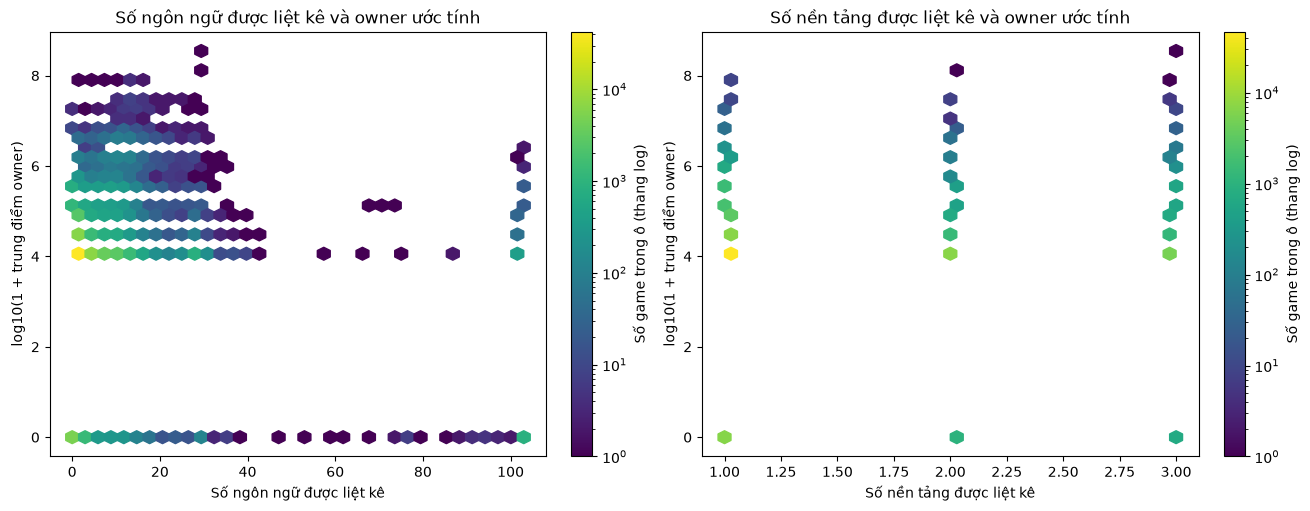

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, x_name, label in zip(axes, ["language_count", "platform_count"], ["Số ngôn ngữ được liệt kê", "Số nền tảng được liệt kê"]):
    hb = ax.hexbin(rq1[x_name], np.log10(rq1["owner_midpoint"] + 1), gridsize=35, mincnt=1, bins="log", cmap="viridis")
    ax.set(title=f"{label} và owner ước tính", xlabel=label, ylabel="log10(1 + trung điểm owner)")
    fig.colorbar(hb, ax=ax, label="Số game trong ô (thang log)")

# Lưu hình ảnh vào thư mục báo cáo
for out_dir in ['reports/figures/q1', 'reports/figure/q1', 'report/figure/q1']:
    Path(out_dir).mkdir(parents=True, exist_ok=True)
    fig.savefig(Path(out_dir) / 'figure1_coverage_owners.png', dpi=300, bbox_inches='tight')
plt.show()


**Nhận xét:** Biểu đồ cho thấy đa số game chỉ có 1 ngôn ngữ, chạy trên 1 nền tảng và có owner thấp. Khi số ngôn ngữ hoặc nền tảng tăng, các vùng có owner cao xuất hiện nhiều hơn, nhưng owner của các game cùng mức độ phủ vẫn chênh nhau rất lớn. Vì vậy, hỗ trợ thêm ngôn ngữ/nền tảng **không phải** là dấu hiệu đủ để dự đoán game sẽ có nhiều owner. Kết quả này phù hợp với hệ số Spearman nhỏ: ρ = 0,153 cho ngôn ngữ và ρ = 0,108 cho nền tảng. Màu đậm chỉ có nghĩa là có nhiều game ở vùng đó; trục dọc log cho phép nhìn đồng thời game có owner thấp và rất cao.

#### Trực quan hóa 2: Mối liên hệ theo thể loại

- **Mục tiêu:** So sánh mối liên hệ giữa số ngôn ngữ/số hệ điều hành và số người sở hữu ước tính ở các thể loại phổ biến.
- **Loại:** Biểu đồ điểm; game đa thể loại có thể thuộc nhiều nhóm.

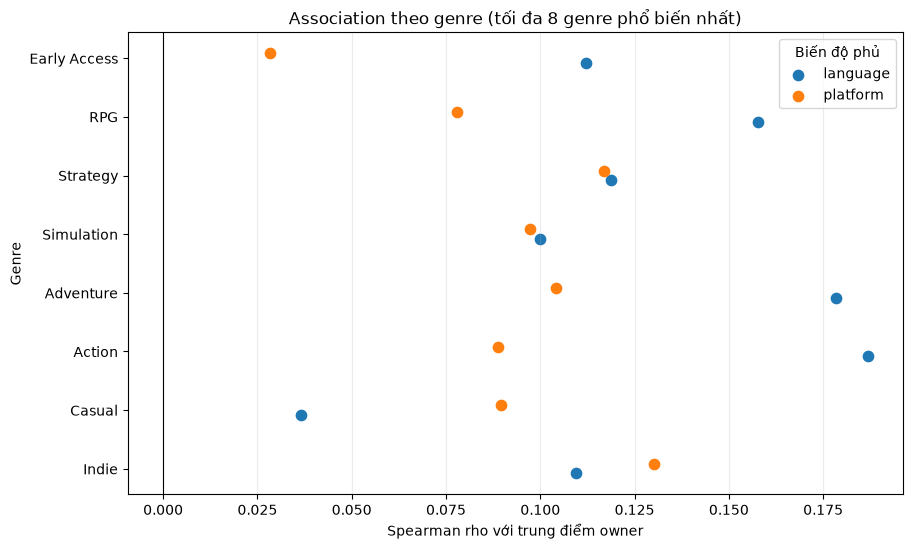

In [5]:
plot_data = pd.DataFrame(genre_correlations)
fig, ax = plt.subplots(figsize=(10, 6))
for i, x_name in enumerate(["language_count", "platform_count"]):
    part = plot_data.loc[plot_data["attribute"].eq(x_name)].set_index("genre").reindex(top_genres)
    ax.scatter(part["rho"], np.arange(len(top_genres)) + (i - 0.5) * 0.16, label=x_name.replace("_count", ""), s=55)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(np.arange(len(top_genres)), top_genres)
ax.set(xlabel="Spearman rho với trung điểm owner", ylabel="Genre", title="Association theo genre (tối đa 8 genre phổ biến nhất)")
ax.legend(title="Biến độ phủ")
ax.grid(axis="x", alpha=0.25)

# Lưu hình ảnh vào thư mục báo cáo
for out_dir in ['reports/figures/q1', 'reports/figure/q1', 'report/figure/q1']:
    Path(out_dir).mkdir(parents=True, exist_ok=True)
    fig.savefig(Path(out_dir) / 'figure2_genre_correlation.png', dpi=300, bbox_inches='tight')
plt.show()


**Nhận xét:** Số ngôn ngữ có liên hệ với owner rõ hơn ở Action (ρ = 0,187) so với Casual (ρ = 0,036). Nói đơn giản: trong nhóm Action, game hỗ trợ nhiều ngôn ngữ thường có owner cao hơn một chút; còn trong nhóm Casual, xu hướng này hầu như không rõ. Số nền tảng có liên hệ yếu ở tất cả các thể loại (ρ từ 0,028 đến 0,130). Các điểm chỉ dùng để mô tả xu hướng trong từng thể loại; chưa đủ để kết luận Action khác Casual một cách chắc chắn, vì một game có thể thuộc nhiều thể loại và các nhóm không hoàn toàn tách biệt.

### 7. Kết quả và thảo luận

**Kết quả chính:** Trong 89.618 game, số ngôn ngữ có liên hệ dương nhưng nhỏ với lượng người sở hữu ước tính (Spearman ρ = 0,153; khoảng tin cậy bootstrap 95%: 0,146–0,161). Số hệ điều hành cũng có liên hệ dương nhỏ (ρ = 0,108; khoảng tin cậy bootstrap 95%: 0,100–0,115). Hệ số càng gần 0 thì mối liên hệ càng yếu.

**Khác biệt giữa các nhóm:** Mối liên hệ giữa số ngôn ngữ và owner cao hơn ở Action (0,187) so với Casual (0,036). Theo tuổi game 0–5, trên 5–10 và trên 10 năm, hệ số lần lượt là 0,119; 0,272; 0,351. Đây là các so sánh riêng từng nhóm, chưa kiểm tra thống kê xem chênh lệch giữa các nhóm có chắc chắn hay không.

**Giả thuyết:** H1 được ủng hộ ở mức yếu: game có độ phủ cao hơn thường có owner cao hơn một chút. H2 và H3 mới có bằng chứng mô tả vì các hệ số thay đổi theo thể loại và tuổi game; chưa có kiểm định trực tiếp để kết luận các nhóm khác nhau một cách chắc chắn.

**Tích hợp dữ liệu (D1):** Nối được 88.813 trong 89.618 game CSV (99,1%) với HF theo mã game; 805 game không khớp dùng số nền tảng từ CSV. Trong các game khớp, số nền tảng từ hai nguồn khác nhau ở 429 trường hợp (0,5%). Các bất đồng này được giữ theo nguồn HF cho mẫu đã khớp và cần được xem xét như giới hạn dữ liệu.

**Ý nghĩa:** Kết quả cho biết hai yếu tố có liên hệ trong dữ liệu, không chứng minh hỗ trợ thêm ngôn ngữ hoặc hệ điều hành làm tăng lượng người sở hữu.

### 8. Kiểm tra độ bền vững

Kết quả vẫn có cùng chiều khi đổi cách tính lượng người sở hữu. Với số ngôn ngữ, hệ số lần lượt là 0,180 (mức thấp), 0,153 (điểm giữa), 0,153 (mức cao), 0,195 khi bỏ khoảng `0–0`, và 0,153 sau khi giới hạn giá trị quá lớn. Với số hệ điều hành, các hệ số tương ứng là 0,118; 0,108; 0,108; 0,121; 0,108.

Khi chia tuổi game theo ba nhóm gần bằng nhau, hệ số số ngôn ngữ tăng từ 0,083 ở nhóm game trẻ lên 0,291 ở nhóm game lâu năm. Khoảng `0–0` chưa rõ ý nghĩa, nên chỉ thử riêng để xem kết quả có đổi không; không xem đây là quy tắc làm sạch mặc định.

### 9. Giới hạn phân tích

- Lượng người sở hữu là ước tính theo khoảng, không phải số đếm chính xác. Điểm giữa chỉ là cách đại diện cho khoảng đó.
- Chưa xác minh được ý nghĩa của khoảng `0–0`; cách hiểu khoảng này có thể ảnh hưởng kết quả.
- Danh sách ngôn ngữ trống được tính là 0 ngôn ngữ được liệt kê; điều đó không chắc có nghĩa game thật sự không hỗ trợ ngôn ngữ nào.
- Một game có thể thuộc nhiều thể loại, nên các nhóm thể loại có thể trùng nhau.
- HF parquet khớp 99,1% mã game trong CSV; một số mã không khớp và 429 game khớp có số nền tảng khác nhau giữa hai nguồn. Sự khác biệt có thể liên quan đến thời điểm hoặc cách ghi nhận, nhưng chưa xác định được nguyên nhân.
- Dữ liệu là ảnh chụp ở một thời điểm. Kết quả chỉ cho biết mối liên hệ, không chứng minh nguyên nhân.

### 10. Kết luận

**Trả lời RQ1:** Có mối liên hệ dương giữa độ phủ hỗ trợ và lượng owner ước tính, nhưng mối liên hệ này nhỏ (ρ = 0,153 với số ngôn ngữ; ρ = 0,108 với số nền tảng). Vì vậy, game có nhiều ngôn ngữ hoặc nền tảng thường có owner cao hơn một chút, nhưng chỉ riêng độ phủ không thể dự đoán owner của một game cụ thể. Xu hướng mạnh hơn ở game lâu năm và thay đổi giữa các thể loại. Kết quả không đổi chiều khi thay cách đại diện khoảng owner, nhưng chỉ là mối liên hệ quan sát được, không chứng minh mở rộng ngôn ngữ hay nền tảng sẽ làm owner tăng.